# 01 — Exploratory data analysis

Reproduces the main figures of `results/report_1_data_audit.md` from `data/processed/pairs.parquet` (run `python scripts/download_data.py` and `python scripts/build_dataset.py` first).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import matplotlib.pyplot as plt
import pandas as pd
from text_utils import tokenize, has_negation_cue
pairs = pd.read_parquet(ROOT / "data/processed/pairs.parquet")
pairs.groupby("split").agg(queries=("query_id", "nunique"), pairs=("query_id", "size"))

,queries,pairs
split,,
test,8956,181701
train,20888,419653


## Candidates per query

count    29844.000000
mean        20.149913
std          9.476979
min          8.000000
25%         16.000000
50%         16.000000
75%         16.000000
max        188.000000
dtype: float64


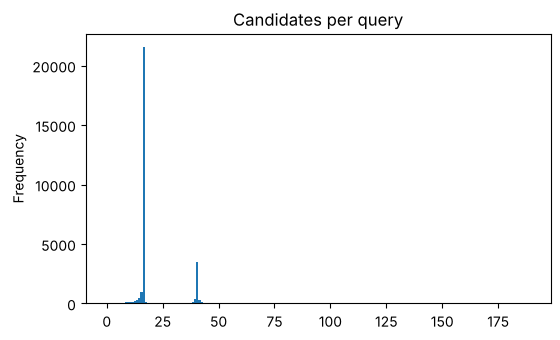

In [2]:
cpq = pairs.groupby("query_id").size()
print(cpq.describe())
cpq.plot.hist(bins=range(0, cpq.max() + 2), title="Candidates per query", figsize=(6, 3.5));

## Label mix and share of Exact per query

esci_label      E      S      C      I
split                                 
test        0.439  0.350  0.045  0.167
train       0.433  0.352  0.045  0.169


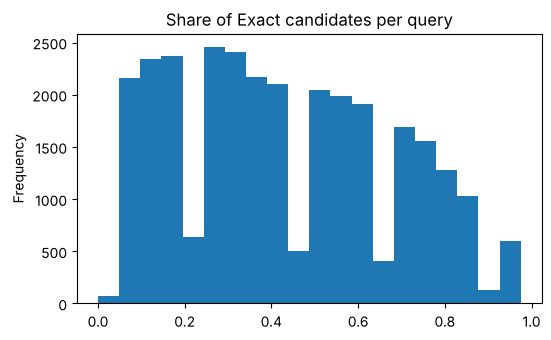

In [3]:
print(pairs.groupby("split")["esci_label"].value_counts(normalize=True).unstack()[["E", "S", "C", "I"]].round(3))
share_e = pairs.groupby("query_id")["esci_label"].apply(lambda s: (s == "E").mean())
share_e.plot.hist(bins=20, title="Share of Exact candidates per query", figsize=(6, 3.5));

## Missing fields

In [4]:
(pairs[["title", "description", "bullets", "brand", "colour"]] == "").groupby(pairs["split"]).mean().T.round(3)

split,test,train
title,0.000,0.000
description,0.500,0.499
bullets,0.118,0.116
brand,0.051,0.049
colour,0.307,0.308


## Query length and query types

digit: 0.209  negation: 0.086


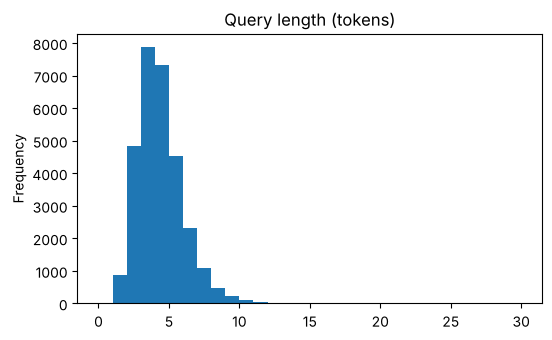

In [5]:
q = pairs.drop_duplicates("query_id")["query"]
qlen = q.map(lambda s: len(tokenize(s)))
print("digit:", q.str.contains(r"\d").mean().round(3), " negation:", q.map(has_negation_cue).mean().round(3))
qlen.plot.hist(bins=range(0, qlen.max() + 2), title="Query length (tokens)", figsize=(6, 3.5));